<a href="https://colab.research.google.com/github/lizlorenzana931109-art/FinPredict-Actividad5/blob/main/fuentes/entrena_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FinPredict | Actividad 5

## Gestión de datos, entrenamiento y ajuste de modelos

**Objetivo:** Desarrollar un modelo de clasificación para predecir el incumplimiento hipotecario utilizando datos sintéticos.

**Alcance:** 50,000 contratos hipotecarios con aperturas escalonadas entre 2021 y 2025.

**Metodología:** Preparación y validación de datos, análisis exploratorio, entrenamiento de Regresión Logística y Random Forest, validación cruzada y registro de experimentos con MLflow.

**Herramientas:** Python, Google Colab, GitHub, scikit-learn y MLflow.

In [1]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 01. Preparación del entorno
# ============================================================

# Instalación de librerías necesarias
%pip -q install mlflow pyarrow

# Librerías para manipulación y análisis de datos
import pandas as pd
import numpy as np
import matplotlib
import sklearn
import pyarrow
import mlflow

# Información del entorno
print("FINPREDICT | Validación del entorno")
print("-" * 45)

print(f"Pandas:        {pd.__version__}")
print(f"NumPy:         {np.__version__}")
print(f"Matplotlib:    {matplotlib.__version__}")
print(f"Scikit-learn:  {sklearn.__version__}")
print(f"PyArrow:       {pyarrow.__version__}")
print(f"MLflow:        {mlflow.__version__}")

print("-" * 45)
print("Entorno preparado correctamente.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 96.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 66.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 02. Configuración y generación de datos sintéticos

### Objetivo

Construir un conjunto de datos sintéticos de 50,000 contratos hipotecarios, con aperturas escalonadas entre enero de 2021 y diciembre de 2025.

La simulación permitirá generar información contractual, sociodemográfica y transaccional para estudiar patrones de comportamiento de pago e identificar señales asociadas al incumplimiento hipotecario.

### Criterios metodológicos

- **Reproducibilidad:** utilización de una semilla aleatoria fija.
- **Consistencia temporal:** los movimientos deberán respetar la fecha de apertura de cada contrato.
- **Consistencia financiera:** los importes y condiciones contractuales deberán seguir reglas de negocio documentadas.
- **Calidad de datos:** se incorporarán inconsistencias controladas para evaluar los procesos de limpieza.
- **Uso responsable:** los datos serán completamente sintéticos y las variables sociodemográficas estarán sujetas a evaluación ética.

Los resultados representarán un escenario simulado y no deberán interpretarse como evidencia del comportamiento real de una cartera hipotecaria.

In [2]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 02. Parámetros generales del dataset
# ============================================================

from datetime import datetime

# Semilla para reproducibilidad
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

# Universo de contratos
NUM_CONTRATOS = 50_000

# Periodo de simulación
FECHA_INICIO = pd.Timestamp("2021-01-01")
FECHA_FIN = pd.Timestamp("2025-12-31")

# Parámetros generales
MONEDA = "MXN"
TIPO_PROBLEMA = "Clasificación binaria"

# Información del proyecto
print("FINPREDICT | Configuración del dataset")
print("-" * 50)
print(f"Contratos:       {NUM_CONTRATOS:,}")
print(f"Periodo:         {FECHA_INICIO.date()} a {FECHA_FIN.date()}")
print(f"Semilla:         {SEMILLA}")
print(f"Moneda:          {MONEDA}")
print(f"Problema:        {TIPO_PROBLEMA}")
print("-" * 50)
print("Configuración inicializada correctamente.")


FINPREDICT | Configuración del dataset
--------------------------------------------------
Contratos:       50,000
Periodo:         2021-01-01 a 2025-12-31
Semilla:         42
Moneda:          MXN
Problema:        Clasificación binaria
--------------------------------------------------
Configuración inicializada correctamente.


In [3]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 03. Generación de identificadores y fechas de apertura
# ============================================================

# Identificadores únicos de los 50,000 contratos
ids_credito = [
    f"HIP{i:06d}"
    for i in range(1, NUM_CONTRATOS + 1)
]

# Fechas aleatorias dentro del periodo definido
dias_periodo = (FECHA_FIN - FECHA_INICIO).days + 1

dias_aleatorios = rng.integers(
    low=0,
    high=dias_periodo,
    size=NUM_CONTRATOS
)

fechas_apertura = (
    FECHA_INICIO + pd.to_timedelta(dias_aleatorios, unit="D")
)

# Tabla inicial de contratos
df_contratos = pd.DataFrame({
    "id_credito": ids_credito,
    "fecha_apertura": fechas_apertura
})

# Ordenar por identificador
df_contratos = df_contratos.sort_values(
    "id_credito"
).reset_index(drop=True)

# Validaciones iniciales
assert len(df_contratos) == NUM_CONTRATOS
assert df_contratos["id_credito"].is_unique
assert df_contratos["fecha_apertura"].between(
    FECHA_INICIO, FECHA_FIN
).all()

print("FINPREDICT | Contratos generados")
print("-" * 45)
print(f"Total de contratos: {len(df_contratos):,}")
print(f"IDs únicos:         {df_contratos['id_credito'].nunique():,}")
print(f"Fecha mínima:       {df_contratos['fecha_apertura'].min().date()}")
print(f"Fecha máxima:       {df_contratos['fecha_apertura'].max().date()}")
print("-" * 45)

display(df_contratos.head(10))


FINPREDICT | Contratos generados
---------------------------------------------
Total de contratos: 50,000
IDs únicos:         50,000
Fecha mínima:       2021-01-01
Fecha máxima:       2025-12-31
---------------------------------------------


,id_credito,fecha_apertura
0,HIP000001,2021-06-12
1,HIP000002,2024-11-14
2,HIP000003,2024-04-10
3,HIP000004,2023-03-13
4,HIP000005,2023-03-02
5,HIP000006,2025-04-17
6,HIP000007,2021-06-06
7,HIP000008,2024-06-27
8,HIP000009,2022-01-03
9,HIP000010,2021-06-21


In [5]:
# Librería para visualización de datos
import matplotlib.pyplot as plt

FINPREDICT | Distribución de aperturas


,contratos,porcentaje
fecha_apertura,,
2021,10016,20.03
2022,9959,19.92
2023,9975,19.95
2024,10144,20.29
2025,9906,19.81


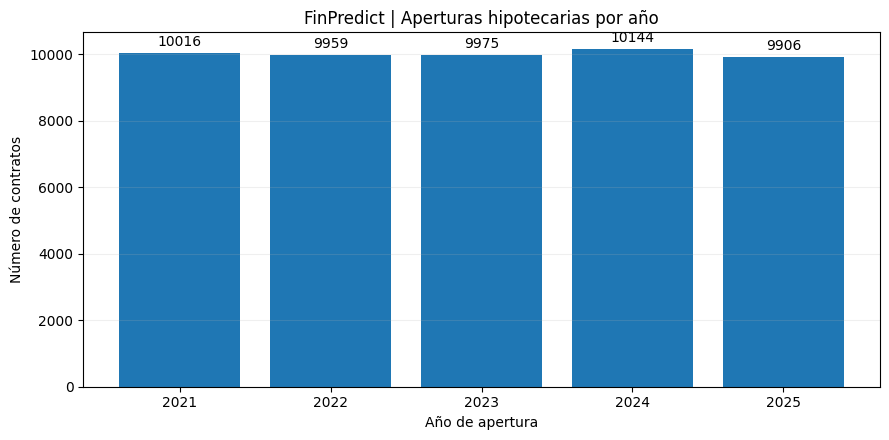

Validación: el universo de contratos está completo.


In [6]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 04. Análisis de aperturas por año
# ============================================================

# Distribución anual
distribucion_anual = (
    df_contratos["fecha_apertura"]
    .dt.year
    .value_counts()
    .sort_index()
)

# Porcentaje por año
resumen_aperturas = pd.DataFrame({
    "contratos": distribucion_anual,
    "porcentaje": (
        distribucion_anual / NUM_CONTRATOS * 100
    ).round(2)
})

print("FINPREDICT | Distribución de aperturas")
display(resumen_aperturas)

# Visualización
fig, ax = plt.subplots(figsize=(9, 4.5))

barras = ax.bar(
    resumen_aperturas.index.astype(str),
    resumen_aperturas["contratos"]
)

ax.bar_label(barras, padding=3, fmt="%.0f")

ax.set_title("FinPredict | Aperturas hipotecarias por año")
ax.set_xlabel("Año de apertura")
ax.set_ylabel("Número de contratos")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

# Validación del universo
assert distribucion_anual.sum() == NUM_CONTRATOS

print("Validación: el universo de contratos está completo.")


### Análisis de distribución temporal

Se generaron 50,000 contratos hipotecarios sintéticos, con fechas de apertura comprendidas entre el 1 de enero de 2021 y el 31 de diciembre de 2025.

El análisis exploratorio identificó una distribución aproximadamente uniforme entre los cinco años, con porcentajes anuales de 19.81% a 20.29%.

El año 2024 presentó la mayor concentración de aperturas (10,144 contratos), mientras que 2025 registró la menor (9,906 contratos).

No se identificaron desequilibrios temporales relevantes en la distribución anual. Este comportamiento es consistente con el mecanismo de generación aleatoria utilizado y no representa una tendencia observada en datos hipotecarios reales.

**Conclusión:** Se valida la distribución inicial de aperturas para continuar con la generación de características contractuales y financieras.